# IA de Score de Crédito

**Objetivo:** prever o score de crédito (`Good`, `Standard` ou `Poor`) de clientes de um banco a partir de dados cadastrais e de comportamento financeiro, e usar essa IA para classificar clientes novos.

**Etapas**
1. Importar e entender os dados
2. Preparar os dados
3. Separar treino e teste
4. Criar e treinar dois modelos (Random Forest e KNN)
5. Avaliar o melhor modelo
6. Prever o score de novos clientes

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, HTML
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

SEMENTE = 42  # seed de aleatoriedade: rodar de novo gera o mesmo resultado

## 1. Importar e entender os dados

In [17]:
tabela = pd.read_csv("../data/clientes.csv")

display(tabela)
display(HTML("<hr>"))
tabela.info()

,id_cliente,mes,idade,profissao,salario_anual,num_contas,num_cartoes,juros_emprestimo,num_emprestimos,dias_atraso,...,idade_historico_credito,investimento_mensal,comportamento_pagamento,saldo_final_mes,score_credito,emprestimo_carro,emprestimo_casa,emprestimo_pessoal,emprestimo_credito,emprestimo_estudantil
0,10002,1,33.0,escritor,16907.79,8.0,6.0,20.0,8.0,40.0,...,139.0,27.80,baixo_gasto_pagamento_baixo,254.92,Poor,0,1,1,0,1
1,10002,2,33.0,escritor,16907.79,8.0,6.0,20.0,8.0,39.0,...,140.0,27.80,alto_gasto_pagamento_baixos,311.43,Poor,0,1,1,0,1
2,10002,3,33.0,escritor,16907.79,8.0,6.0,20.0,8.0,35.0,...,141.0,27.80,alto_gasto_pagamento_alto,345.28,Poor,0,1,1,0,1
3,10002,4,33.0,escritor,16907.79,8.0,6.0,20.0,8.0,37.0,...,142.0,27.80,alto_gasto_pagamento_baixos,191.22,Poor,0,1,1,0,1
4,10002,5,33.0,escritor,16907.79,8.0,6.0,20.0,8.0,39.0,...,143.0,27.80,baixo_gasto_pagamento_alto,288.19,Poor,0,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,99969,4,40.0,contador,40373.72,2.0,7.0,5.0,2.0,12.0,...,344.0,47.48,alto_gasto_pagamento_alto,424.48,Poor,0,1,0,1,0
49996,99969,5,40.0,contador,40373.72,2.0,7.0,5.0,2.0,13.0,...,345.0,47.48,alto_gasto_pagamento_alto,376.45,Poor,0,1,0,1,0
49997,99969,6,41.0,contador,40373.72,2.0,7.0,5.0,2.0,13.0,...,346.0,47.48,alto_gasto_pagamento_medio,424.93,Poor,0,1,0,1,0
49998,99969,7,41.0,contador,40373.72,2.0,7.0,5.0,2.0,16.0,...,347.0,47.48,baixo_gasto_pagamento_baixo,57.42,Poor,0,1,0,1,0


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_cliente                50000 non-null  int64  
 1   mes                       50000 non-null  int64  
 2   idade                     50000 non-null  float64
 3   profissao                 50000 non-null  str    
 4   salario_anual             50000 non-null  float64
 5   num_contas                50000 non-null  float64
 6   num_cartoes               50000 non-null  float64
 7   juros_emprestimo          50000 non-null  float64
 8   num_emprestimos           50000 non-null  float64
 9   dias_atraso               50000 non-null  float64
 10  num_pagamentos_atrasados  50000 non-null  float64
 11  num_verificacoes_credito  50000 non-null  float64
 12  mix_credito               50000 non-null  str    
 13  divida_total              50000 non-null  float64
 14  taxa_uso_credito 

In [22]:
print("Proporção de cada score na base:")
display(HTML("<br>"))
display(tabela["score_credito"].value_counts(normalize=True))
display(HTML("<hr>"))
print(f"{len(tabela)} linhas de {tabela['id_cliente'].nunique()} clientes")
tabela.groupby("id_cliente").size().value_counts().rename("clientes com N registros")

Proporção de cada score na base:


score_credito
Standard    0.54306
Poor        0.29414
Good        0.16280
Name: proportion, dtype: float64

50000 linhas de 6250 clientes


8    6250
Name: clientes com N registros, dtype: int64

Cada cliente aparece **várias vezes**, um registro por mês. Isso vai importar na hora de separar treino e teste.

## 2. Preparar os dados

A IA só trabalha com números, então as colunas de texto(`profissao`, `mix_credito` e `comportamento_pagamento`) precisam ser convertidas. A coluna que queremos prever(`score_credito`) permanece.

> A conversão fica dentro de um **Pipeline**: ela é aprendida uma vez no treino e reaplicada do mesmo jeito em qualquer nova leitura.

In [23]:
COLUNAS_TEXTO = ["profissao", "mix_credito", "comportamento_pagamento"]

y = tabela["score_credito"]                            # o que a IA vai prever
x = tabela.drop(columns=["id_cliente", "score_credito"])  # o que a IA usa para prever
grupos = tabela["id_cliente"]                          # usado so para separar treino/teste

## 3. Separar treino e teste

70% dos clientes vão para o treino e 30% para o teste.

>A separação é feita **por cliente**, não por linha. Se fosse por linha, o mesmo cliente apareceria nos dois lados (com meses diferentes, mas dados identicos), e a IA acertaria o teste por "aprender" o cliente, não por ter aprendido o padrão. A acurácia ficaria inflada e não representaria o desempenho em clientes realmente novos.

In [7]:
divisor = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=SEMENTE)
idx_treino, idx_teste = next(divisor.split(x, y, groups=grupos))

x_treino, x_teste = x.iloc[idx_treino], x.iloc[idx_teste]
y_treino, y_teste = y.iloc[idx_treino], y.iloc[idx_teste]

print(f"Treino: {grupos.iloc[idx_treino].nunique()} clientes ({len(x_treino)} linhas)")
print(f"Teste:  {grupos.iloc[idx_teste].nunique()} clientes ({len(x_teste)} linhas)")

Treino: 4375 clientes (35000 linhas)
Teste:  1875 clientes (15000 linhas)


## 4. Criar e treinar os modelos

- **Random Forest:** várias árvores de decisão que votam no resultado. Árvores não ligam para a escala dos números, então basta numerar as categorias.
- **KNN (vizinhos mais próximos):** classifica cada cliente olhando os clientes mais parecidos com ele. Como mede distâncias, os números precisam estar na mesma escala (senão o salário, na casa dos milhares, pesa muito mais que a idade ou o número de cartões), e cada categoria vira uma coluna 0/1.

In [8]:
preparo_floresta = ColumnTransformer(
    [("texto", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), COLUNAS_TEXTO)],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

preparo_knn = ColumnTransformer([
    ("texto", OneHotEncoder(handle_unknown="ignore"), COLUNAS_TEXTO),
    ("numeros", StandardScaler(), make_column_selector(dtype_include="number")),
])

modelos = {
    "Random Forest": Pipeline([
        ("preparo", preparo_floresta),
        ("modelo", RandomForestClassifier(random_state=SEMENTE, n_jobs=-1)),
    ]),
    "KNN": Pipeline([
        ("preparo", preparo_knn),
        ("modelo", KNeighborsClassifier()),
    ]),
}

In [9]:
acuracias = {}
for nome, modelo in modelos.items():
    modelo.fit(x_treino, y_treino)
    acuracias[nome] = accuracy_score(y_teste, modelo.predict(x_teste))
    print(f"{nome}: {acuracias[nome]:.1%} de acerto")

Random Forest: 64.0% de acerto


KNN: 54.9% de acerto


### E se a divisão fosse por linha?
Para ver o efeito de misturar o mesmo cliente no treino e no teste, o Random Forest é treinado de novo com uma divisão aleatória por linha, como na primeira versão do projeto.

In [10]:
x_treino_l, x_teste_l, y_treino_l, y_teste_l = train_test_split(x, y, test_size=0.3, random_state=SEMENTE)
floresta_linha = clone(modelos["Random Forest"]).fit(x_treino_l, y_treino_l)

print(f"Divisão por linha:   {accuracy_score(y_teste_l, floresta_linha.predict(x_teste_l)):.1%}")
print(f"Divisão por cliente: {acuracias['Random Forest']:.1%}")

Divisão por linha:   80.3%
Divisão por cliente: 64.0%


A divisão por linha parece bem melhor, mas é ilusão: o modelo já viu os mesmos clientes (em outros meses) no treino. A divisão por cliente mede o que interessa, que é o acerto em clientes que o modelo nunca viu.

## 5. Avaliar o melhor modelo

In [11]:
melhor_nome = max(acuracias, key=acuracias.get)
melhor = modelos[melhor_nome]
previsao_teste = melhor.predict(x_teste)

print(f"Melhor modelo: {melhor_nome}\n")
print(classification_report(y_teste, previsao_teste))

Melhor modelo: Random Forest

              precision    recall  f1-score   support

        Good       0.57      0.59      0.58      2578
        Poor       0.60      0.50      0.54      4353
    Standard       0.68      0.73      0.70      8069

    accuracy                           0.64     15000
   macro avg       0.62      0.61      0.61     15000
weighted avg       0.64      0.64      0.64     15000



- **precision:** dos clientes que a IA classificou como aquele score, quantos realmente eram.
- **recall:** dos clientes que realmente tinham aquele score, quantos a IA encontrou.

### Matriz de confusão: onde a IA erra
Cada linha é o score real; cada coluna, o que a IA previu. A diagonal são os acertos.

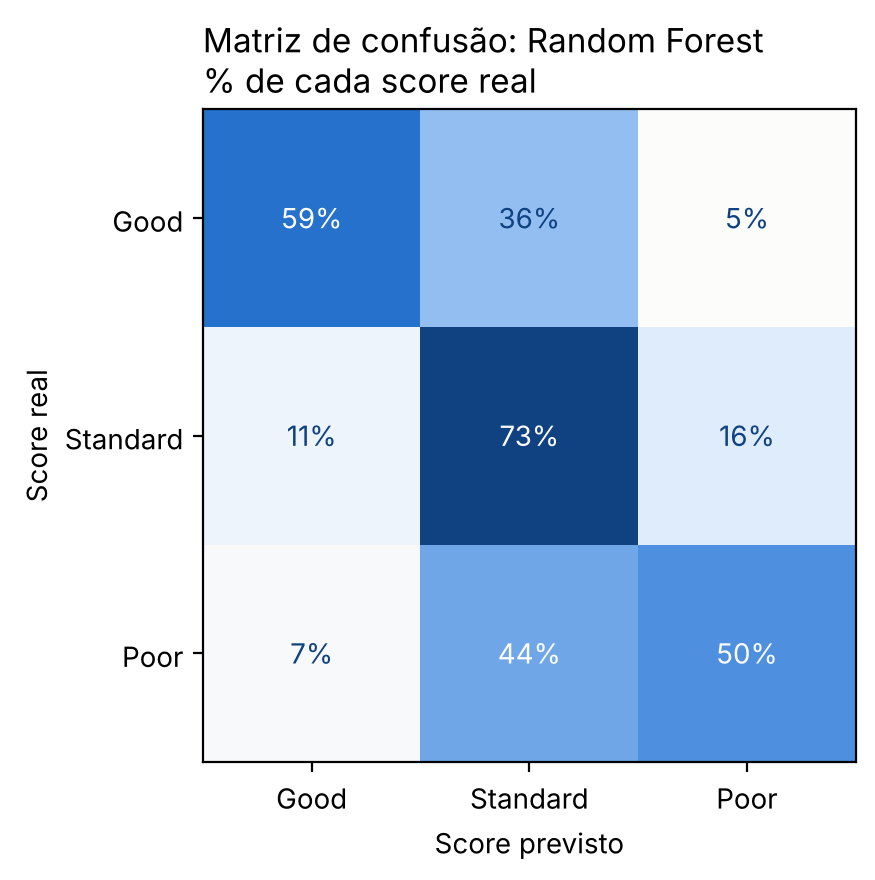

In [12]:
AZUIS = LinearSegmentedColormap.from_list("azuis", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#104281"])
ORDEM_SCORE = ["Good", "Standard", "Poor"]

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_teste, previsao_teste, labels=ORDEM_SCORE, normalize="true",
    values_format=".0%", cmap=AZUIS, colorbar=False, ax=ax,
)
ax.set_title(f"Matriz de confusão: {melhor_nome}\n% de cada score real", loc="left")
ax.set_xlabel("Score previsto")
ax.set_ylabel("Score real")
plt.tight_layout()
plt.show()

### Quais informações mais pesam na decisão
O Random Forest mede quanto cada coluna ajudou a separar os scores.

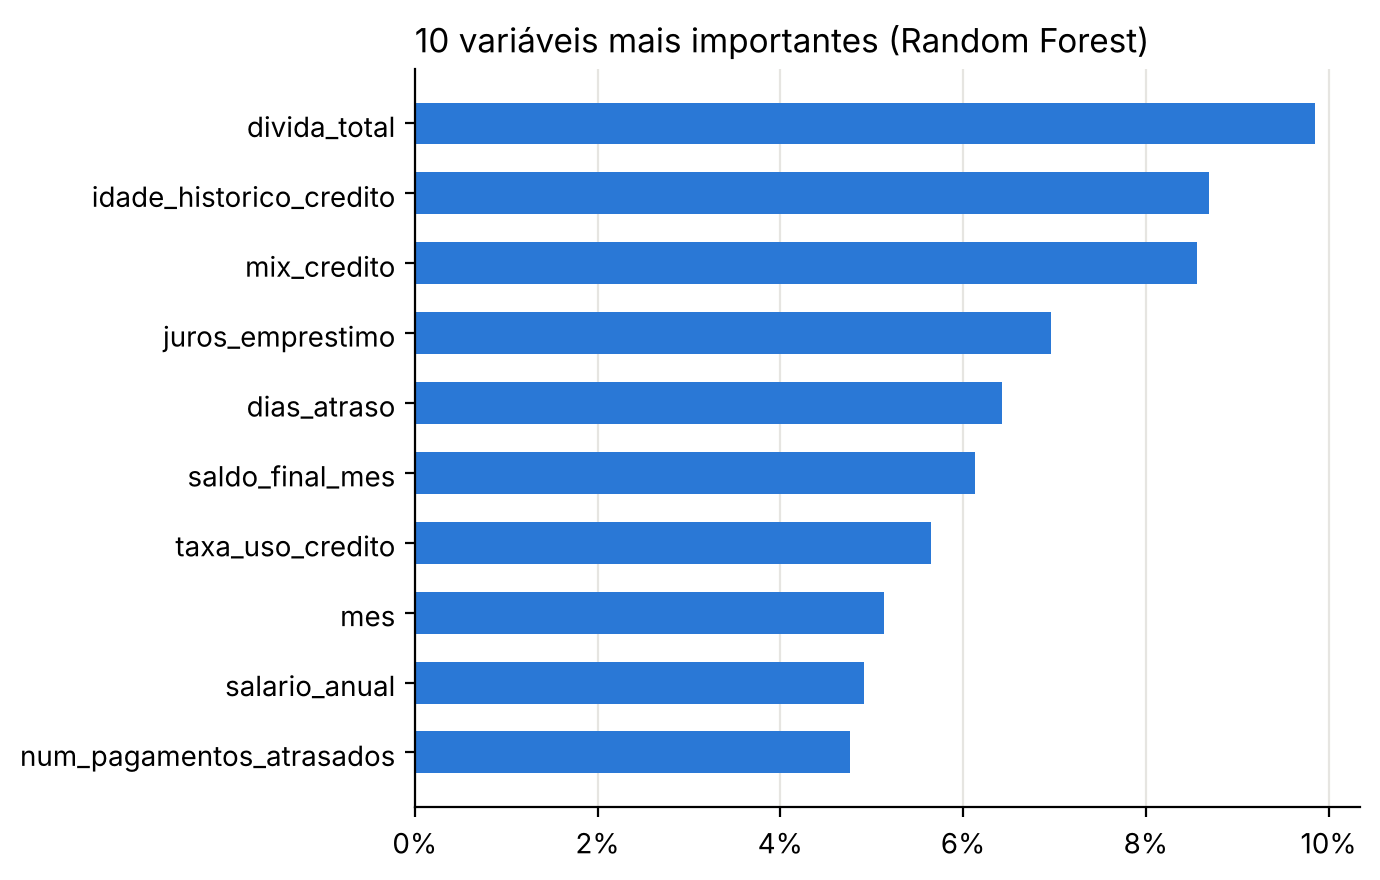

In [13]:
floresta = modelos["Random Forest"]
importancias = pd.Series(
    floresta.named_steps["modelo"].feature_importances_,
    index=floresta.named_steps["preparo"].get_feature_names_out(),
)
top10 = importancias.sort_values().tail(10)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top10.index, top10.values, color="#2a78d6", height=0.6)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_title("10 variáveis mais importantes (Random Forest)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e6e5e1", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 6. Prever o score de novos clientes

Antes de usar a IA para valer, o melhor modelo é treinado de novo com **todos** os clientes (treino + teste): mais dados, modelo melhor. A avaliação acima continua valendo como estimativa de desempenho.

>Repare que aqui **não preciso** "transformar"(colunas-> numeros) nos novos clientes: o pipeline converte as colunas de texto exatamente como aprendeu no treino.

In [14]:
modelo_final = clone(melhor).fit(x, y)

novos_clientes = pd.read_csv("../data/novos_clientes.csv")
novos_clientes["score_previsto"] = modelo_final.predict(novos_clientes[x.columns])
display(novos_clientes)

,mes,idade,profissao,salario_anual,num_contas,num_cartoes,juros_emprestimo,num_emprestimos,dias_atraso,num_pagamentos_atrasados,...,idade_historico_credito,investimento_mensal,comportamento_pagamento,saldo_final_mes,emprestimo_carro,emprestimo_casa,emprestimo_pessoal,emprestimo_credito,emprestimo_estudantil,score_previsto
0,5,29.0,engenheiro,20826.66,9.0,7.0,20.0,7.0,51.0,13.0,...,57.0,32.88,alto_gasto_pagamento_medio,323.78,0,1,0,0,1,Standard
1,5,15.0,advogado,16988.76,8.0,7.0,24.0,4.0,28.0,17.0,...,25.0,19.54,baixo_gasto_pagamento_baixo,220.90,0,1,1,1,0,Poor
2,7,25.0,gerente_midia,19604.07,1.0,5.0,9.0,3.0,21.0,12.0,...,158.0,29.09,baixo_gasto_pagamento_baixo,229.31,0,1,0,0,1,Standard
3,1,21.0,arquiteto,14729.53,8.0,3.0,13.0,0.0,38.0,21.0,...,227.0,21.17,baixo_gasto_pagamento_baixo,343.10,0,0,0,0,0,Standard
4,5,24.0,desenvolvedor,14925.76,8.0,7.0,29.0,4.0,18.0,21.0,...,182.0,39.24,baixo_gasto_pagamento_baixo,217.23,1,0,1,0,1,Poor
5,6,35.0,advogado,17024.19,8.0,9.0,24.0,4.0,27.0,22.0,...,205.0,39.18,alto_gasto_pagamento_alto,345.19,0,1,0,1,1,Poor
6,8,17.0,escritor,145002.83,6.0,3.0,15.0,2.0,13.0,4.0,...,384.0,151.63,alto_gasto_pagamento_alto,851.25,0,0,0,0,1,Good
7,7,38.0,musico,33606.07,1.0,4.0,5.0,2.0,9.0,16.0,...,277.0,33.98,alto_gasto_pagamento_baixos,388.93,0,0,0,0,0,Good
8,4,32.0,gerente,18470.74,3.0,4.0,8.0,2.0,13.0,17.0,...,277.0,38.30,alto_gasto_pagamento_baixos,295.74,0,0,0,0,1,Standard
9,8,45.0,gerente,102904.41,0.0,3.0,1.0,0.0,2.0,0.0,...,368.0,111.57,alto_gasto_pagamento_alto,807.14,0,0,0,0,0,Good
